# Lab 02

### Step 1 Import libraries and verify environment

In [31]:
import sys
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Python executable:", sys.executable)
print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

Python executable: c:\Users\jawah_czbwkdr\AppData\Local\Python\pythoncore-3.14-64\python.exe
OpenCV version: 5.0.0
NumPy version: 2.5.4
Matplotlib version: 3.11.2


### Step 2: Load the image 

In [32]:
IMAGE_PATH = "my_image.png"

image_bgr = cv.imread(IMAGE_PATH, cv.IMREAD_COLOR)

if image_bgr is None:
    raise FileNotFoundError(
        f"Could not load '{IMAGE_PATH}'. Check the filename and folder."
    )

print("Image loaded successfully.")
print("Image shape:", image_bgr.shape)
print("Data type:", image_bgr.dtype)

if image_bgr.shape[0] < 300 or image_bgr.shape[1] < 300:
    raise ValueError("Please select an image at least 300 x 300 pixels.")

Image loaded successfully.
Image shape: (506, 528, 3)
Data type: uint8


### Step 3: Inspect dimensions, pixels and intensity ranges

In [33]:
height, width, channels = image_bgr.shape

print("Height:", height)
print("Width:", width)
print("Number of channels:", channels)

top_left_pixel = image_bgr[0, 0]
center_pixel_bgr = image_bgr[height // 2, width // 2]

print("Top-left pixel (BGR):", top_left_pixel)
print("Center pixel (BGR):", center_pixel_bgr)

print("Global minimum:", image_bgr.min())
print("Global maximum:", image_bgr.max())

for index, name in enumerate(["Blue", "Green", "Red"]):
    channel = image_bgr[:, :, index]
    print(f"{name} channel minimum:", channel.min())
    print(f"{name} channel maximum:", channel.max())

Height: 506
Width: 528
Number of channels: 3
Top-left pixel (BGR): [29 29 29]
Center pixel (BGR): [97 55  6]
Global minimum: 0
Global maximum: 255
Blue channel minimum: 0
Blue channel maximum: 255
Green channel minimum: 0
Green channel maximum: 255
Red channel minimum: 0
Red channel maximum: 255


### Step 4: Convert colors and display six views

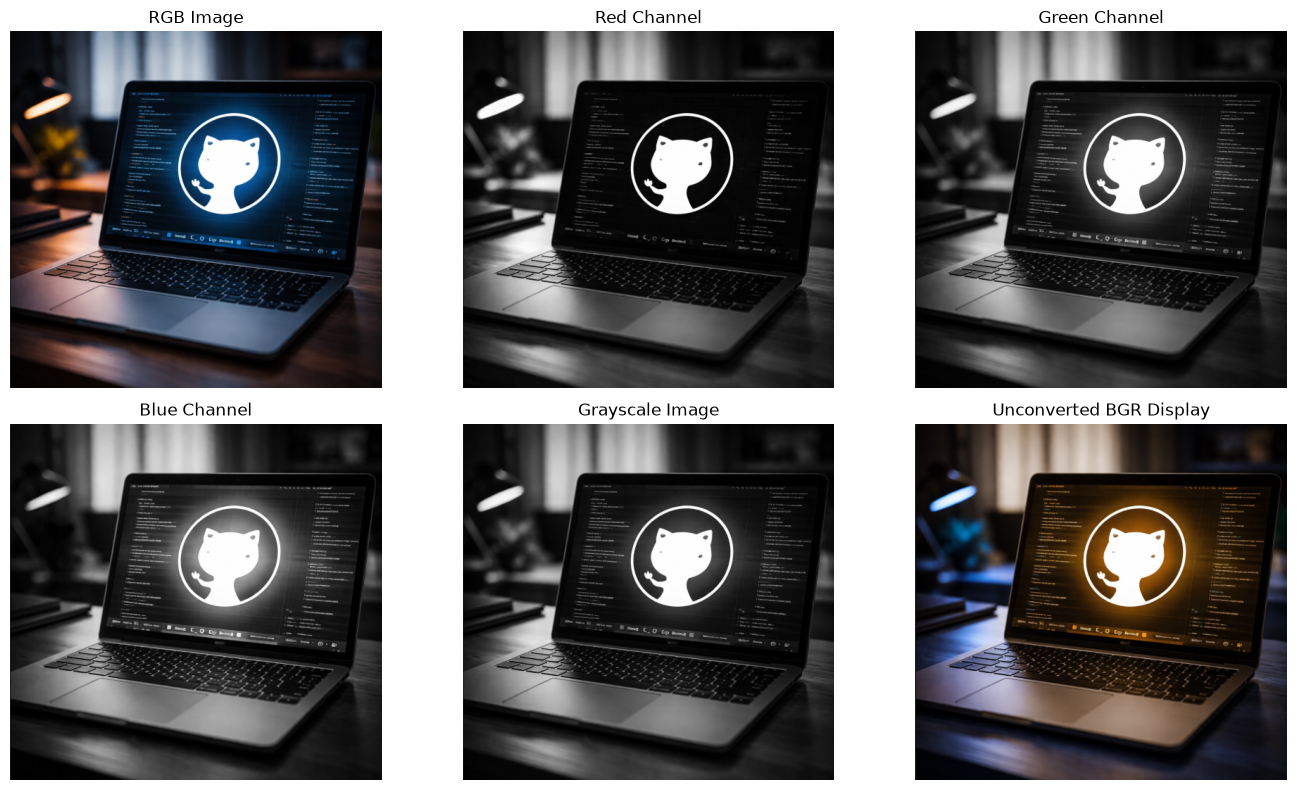

In [34]:
image_rgb = cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)
gray_image = cv.cvtColor(image_bgr, cv.COLOR_BGR2GRAY)

blue_channel = image_bgr[:, :, 0]
green_channel = image_bgr[:, :, 1]
red_channel = image_bgr[:, :, 2]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title("RGB Image")

axes[0, 1].imshow(red_channel, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Red Channel")

axes[0, 2].imshow(green_channel, cmap="gray", vmin=0, vmax=255)
axes[0, 2].set_title("Green Channel")

axes[1, 0].imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Blue Channel")

axes[1, 1].imshow(gray_image, cmap="gray")
axes[1, 1].set_title("Grayscale Image")

axes[1, 2].imshow(image_bgr)
axes[1, 2].set_title("Unconverted BGR Display")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### For HEX value of Center pixel  

In [35]:
center_pixel_rgb = image_rgb[height // 2, width // 2]
r, g, b = map(int, center_pixel_rgb)

hex_color = f"#{r:02X}{g:02X}{b:02X}"

print("Center pixel (RGB):", center_pixel_rgb)
print("Center pixel HEX:", hex_color)

Center pixel (RGB): [ 6 55 97]
Center pixel HEX: #063761


### Step 5: Crop, resize and save

Crop shape: (100, 100, 3)
Resized image shape: (200, 200, 3)


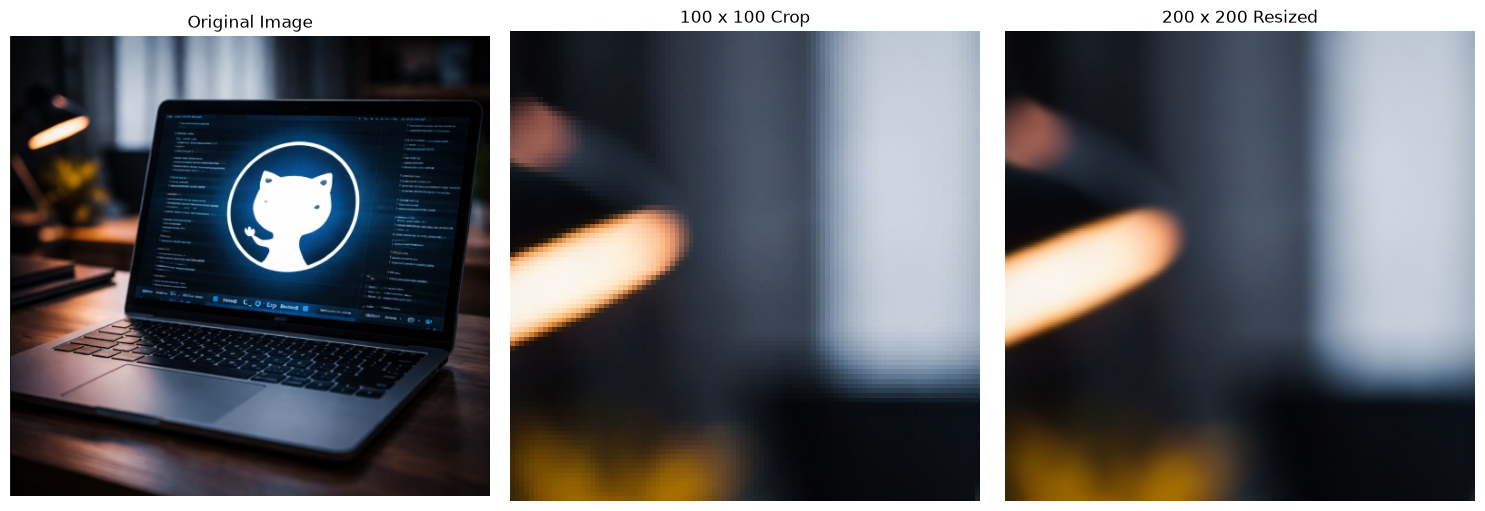

resized_crop.png saved successfully: True


In [36]:
x_start = 50
y_start = 50
x_end = x_start + 100
y_end = y_start + 100

# Crop using [y_start:y_end, x_start:x_end]
crop_rgb = image_rgb[y_start:y_end, x_start:x_end]

if crop_rgb.shape[:2] != (100, 100):
    raise ValueError("Crop must be exactly 100 x 100 pixels.")

print("Crop shape:", crop_rgb.shape)

# Resize to 200 x 200
resized_rgb = cv.resize(crop_rgb, (200, 200))

print("Resized image shape:", resized_rgb.shape)

# Display original, crop and resized image
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(crop_rgb)
axes[1].set_title("100 x 100 Crop")

axes[2].imshow(resized_rgb)
axes[2].set_title("200 x 200 Resized")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Convert RGB to BGR before saving through OpenCV
resized_bgr = cv.cvtColor(resized_rgb, cv.COLOR_RGB2BGR)

save_success = cv.imwrite("resized_crop.png", resized_bgr)

print("resized_crop.png saved successfully:", save_success)

if not save_success:
    raise IOError("Could not save resized_crop.png")

### 6: Create and save grayscale histogram

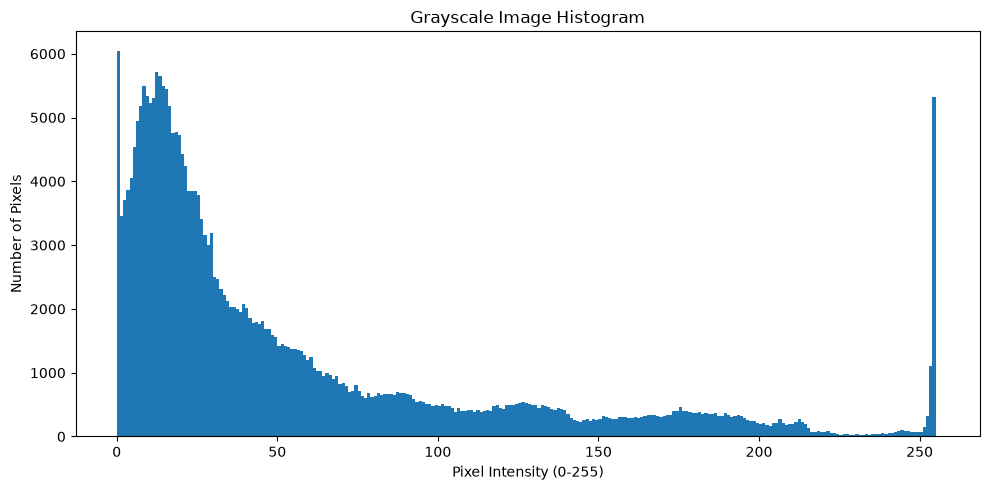

Histogram saved as grayscale_histogram.png


In [38]:
gray_pixels = gray_image.flatten()

plt.figure(figsize=(10, 5))
plt.hist(gray_pixels, bins=256, range=(0, 256))

plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")

plt.tight_layout()
plt.savefig("grayscale_histogram.png", dpi=150)
plt.show()

print("Histogram saved as grayscale_histogram.png")

### Step7: Analyze histogram

In [39]:
dark_pixels = np.count_nonzero(gray_image < 85)
mid_pixels = np.count_nonzero(
    (gray_image >= 85) & (gray_image < 170)
)
bright_pixels = np.count_nonzero(gray_image >= 170)

total_pixels = gray_image.size

print(f"Dark pixels (0-84): {dark_pixels} "
      f"({dark_pixels / total_pixels * 100:.2f}%)")

print(f"Mid-tone pixels (85-169): {mid_pixels} "
      f"({mid_pixels / total_pixels * 100:.2f}%)")

print(f"Bright pixels (170-255): {bright_pixels} "
      f"({bright_pixels / total_pixels * 100:.2f}%)")

Dark pixels (0-84): 208959 (78.21%)
Mid-tone pixels (85-169): 35833 (13.41%)
Bright pixels (170-255): 22376 (8.38%)


### Step 8: Demonstrate bit depth

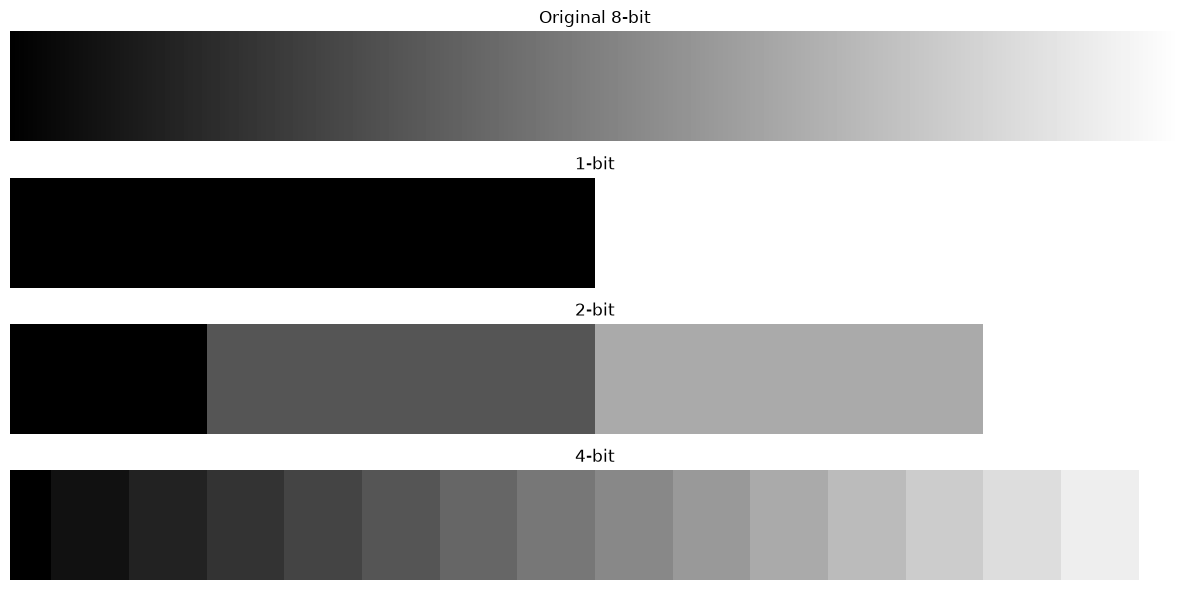

Original 8-bit unique-value count: 256
1-bit unique-value count: 2
2-bit unique-value count: 4
4-bit unique-value count: 16


In [40]:
# Create an 8-bit horizontal grayscale gradient
gradient = np.arange(256, dtype=np.uint8)

def quantize_gradient(values, bits):
    levels = 2 ** bits

    quantized_levels = np.round(
        values.astype(np.float32) * (levels - 1) / 255
    )

    return np.round(
        quantized_levels * 255 / (levels - 1)
    ).astype(np.uint8)


gradient_1bit = quantize_gradient(gradient, 1)
gradient_2bit = quantize_gradient(gradient, 2)
gradient_4bit = quantize_gradient(gradient, 4)

gradients = [
    ("Original 8-bit", gradient),
    ("1-bit", gradient_1bit),
    ("2-bit", gradient_2bit),
    ("4-bit", gradient_4bit),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for ax, (title, values) in zip(axes, gradients):
    gradient_image = np.tile(values, (30, 1))
    ax.imshow(
        gradient_image,
        cmap="gray",
        vmin=0,
        vmax=255,
        aspect="auto"
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

for title, values in gradients:
    print(f"{title} unique-value count:",
          len(np.unique(values)))

### Final verification

In [41]:
import os

required_files = [
    IMAGE_PATH,
    "resized_crop.png",
    "grayscale_histogram.png"
]

print("Final output files:")

for filename in required_files:
    print(f"{filename}: {'Found' if os.path.isfile(filename) else 'Missing'}")

Final output files:
my_image.png: Found
resized_crop.png: Found
grayscale_histogram.png: Found
